## Homework 4 - Analysis Using Hotelling's $T^2$ and Multiple Stream Process Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: November 20, 2026 via D2L**

## Instructions:

You are the director of The Owl's Nest, a psychological services program at a local university that employs a team of four Clinical Psychology PhD students to offer counseling services to the campus community at a steep discount. When a new client comes in, they commit to biweekly sessions for at least one semester. At the start of each session, the client completes a brief survey assessing depressive symptoms using Likert-scale items (e.g., "How much do you agree with this statement, on a scale from 1 (strongly disagree) to 5 (strongly agree)?"). The total score ranges from 20 to 100, with higher scores indicating more severe depressive symptoms.

If a counselor's client scores begin trending upward over time, that may indicate a need for you, as the director, to step in -- whether by providing additional training and supervision, or by referring a client to a higher level of care. Because all four counselors work in the same training program, share office space and supervision, and often see clients during the same high-stress points in the academic calendar (midterms, finals), you suspect their clients' scores may be correlated with one another from week to week, rather than behaving as four completely independent processes.

To monitor this, you perform an initial Phase I analysis, jointly monitoring the scores of all four counselors across the 16-week fall semester, taking a sample of 5 clients per week for each counselor. After confirming statistical control, you'll monitor the subsequent 16-week spring semester (Phase II) to determine whether anything has changed.

## Key Specifications

| Quantity | Value |
|---|---|
| Quality characteristic | Total depressive-symptom survey score (20-100 scale) |
| Number of counselors (streams) | 4 |
| Clients sampled per counselor per week (n) | 5 |
| Phase I weeks (m) | 16 (fall semester) |
| Phase II weeks (m) | 16 (spring semester) |
| Control Chart for Each Stream design value | $L = 3.46$ |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis
- The purpose of this analysis is to evaulate the quality of a psychological services program, the Owl's nest. The main objective is to determine the program's effectiveness in treating depressive symptoms.
- Monitoring with control charts that capture the interdependece of these processes to avoid missing the bigger picture. Ultimately, to view trends, out of control points, and to make more informed decsions in regards to the programs changes.       
### Q2: Identify the quality characteristic being monitored, and classify its measurement scale. Why might it be reasonable to suspect that the four counselors' weekly scores are correlated with one another, rather than fully independent?
- The quality characteristic is the summation of the depressive-symptom score(20-100) which is a continuous variable.
- It is reasonable to suspect that the weekly scores among the counselors are correlated in that they, "work in the same training program, share office space and supervision, and often see clients during the same high-stress points in the academic calendar (midterms, finals)".     
### Q3: Given your answer to Q2, briefly explain why it might be reasonable to treat this scenario as a **multivariate process** (suggesting a Hotelling's $T^2$ chart) rather than a **multiple stream process** (suggesting the Control Chart for Each Stream technique). Under what different assumption would the opposite framing make more sense?
- The key thing is we suspect the councelor's scores are correlated with one another & not independent. With that in mind it would be more appropiate to consider multivariate process instead of multiple stream process.
- Now if we beleive the processes to be independet of each other but share the same target value. It would then be more appropiate to consider multiple stream process.     

## Analyze

### Q4: Read the Phase I data (`Counselling_PhaseI.xlsx`) into R as a list, one data frame per counselor (HINT: use `qcc::mqcc`, and make sure to remove the `Week` column from each data frame, possibly using `lapply`). Construct a Phase I Hotelling's $T^2$ chart. Do we have evidence of statistical control? Why or why not?

In [1]:
## Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "tchoud227"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}

# Change the working directory to the specific assignment folder within the cloned repository
setwd(file.path(repo_name, "Assignments", "HW4"))

In [2]:
getwd()

[1] "/content/STAT-7110-Quality-Control/Assignments/HW4"

In [3]:
install.packages(c("tidyverse", "readxl", "qcc", "ggplot2"))

library(tidyverse)
library(readxl)
library(qcc)
library(ggplot2)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.4     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Package 'qcc' version 2.7

Type 'citation("qcc")' for citing this R package in publications.



In [6]:
## Q4 Code ##
sn <- excel_sheets("Counselling_PhaseI.xlsx")

# Removing week from each sheet
owlNest <- lapply(sn, FUN=function(x){
    d <- read_excel("Counselling_PhaseI.xlsx", sheet = x) |>
    dplyr::select(-'Week')

    return(d)
})

names(owlNest) <- paste("Counselor", 1:4, sep="")
owlNest["Counselor1"]

Client1,Client2,Client3,Client4,Client5
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
39.99,46.47,38.31,57.76,47.64
52.35,51.26,45.60,29.09,49.96
43.68,42.97,50.58,49.45,39.49
64.21,44.69,50.52,45.22,39.05
40.45,43.92,54.42,32.81,49.75
40.04,45.34,37.71,46.26,39.76
40.95,55.74,43.28,43.56,44.20
29.69,54.41,31.68,41.29,36.07
48.40,43.09,53.47,52.09,40.05


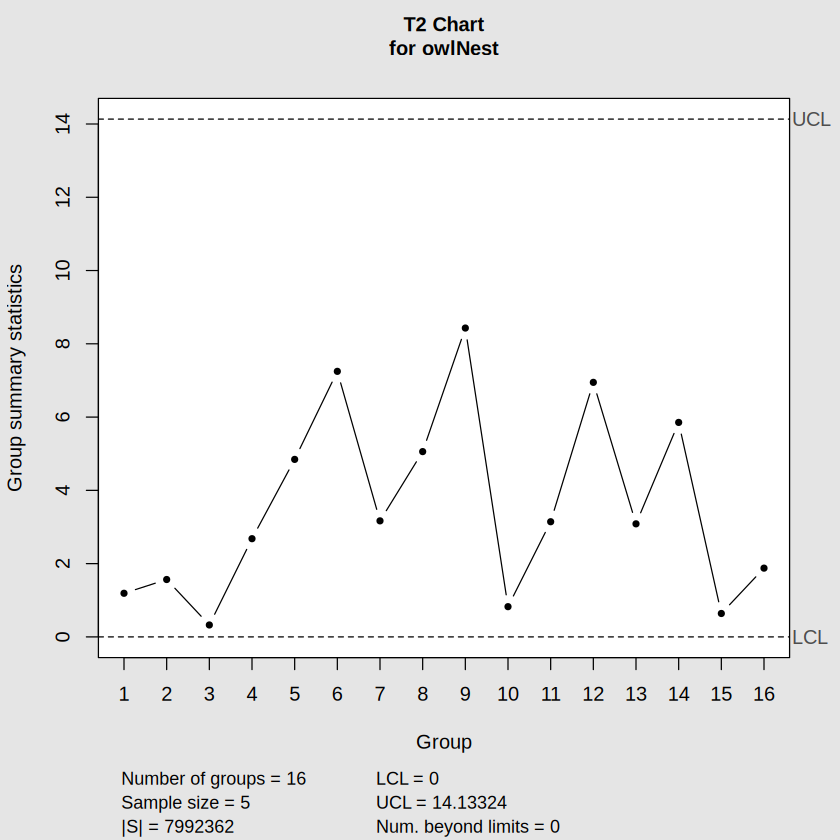

In [8]:
# mqcc for plotting the phase 1 chart
t2 <- mqcc(owlNest, type = 'T2')

This T2 chart supports the evidence of statistical control in that:
- All points are within the control limits or no out of control points.
- No obvious pattern/trend.

### Q5: Report the sample mean vector and sample variance-covariance matrix from Q4.

In [12]:
## Q5 Code ##
# sample mean vectore
print(t2$center)

# sample variance-covariance matrix
print(t2$cov)

Counselor1 Counselor2 Counselor3 Counselor4 
  45.34275   46.00288   45.28650   45.45975 
[1] "/n/n"
           Counselor1 Counselor2 Counselor3 Counselor4
Counselor1   64.94685   25.20394   18.73784   28.36822
Counselor2   25.20394   63.96758   30.76070   26.36930
Counselor3   18.73784   30.76070   67.29034   14.95226
Counselor4   28.36822   26.36930   14.95226   60.67095


### Q6: Read the Phase II data (`Counselling_PhaseII.xlsx`) into R the same way. Using the mean vector and covariance matrix from Q5, construct a Phase II Hotelling's $T^2$ chart. Do we still have evidence of statistical control? If not, generate individual univariate Shewhart $\bar{X}$ and $s$ charts (using the appropriate mean and standard deviation from Phase I) to determine which counselor(s) may have out-of-control scores.

In [14]:
## Q6 Code ##
sn <- excel_sheets("Counselling_PhaseII.xlsx")

# Removing week from each sheet
owlNest2 <- lapply(sn, FUN=function(x){
    d <- read_excel("Counselling_PhaseII.xlsx", sheet = x) |>
    dplyr::select(-'Week')

    return(d)
})

names(owlNest2) <- paste("Counselor", 1:4, sep="")

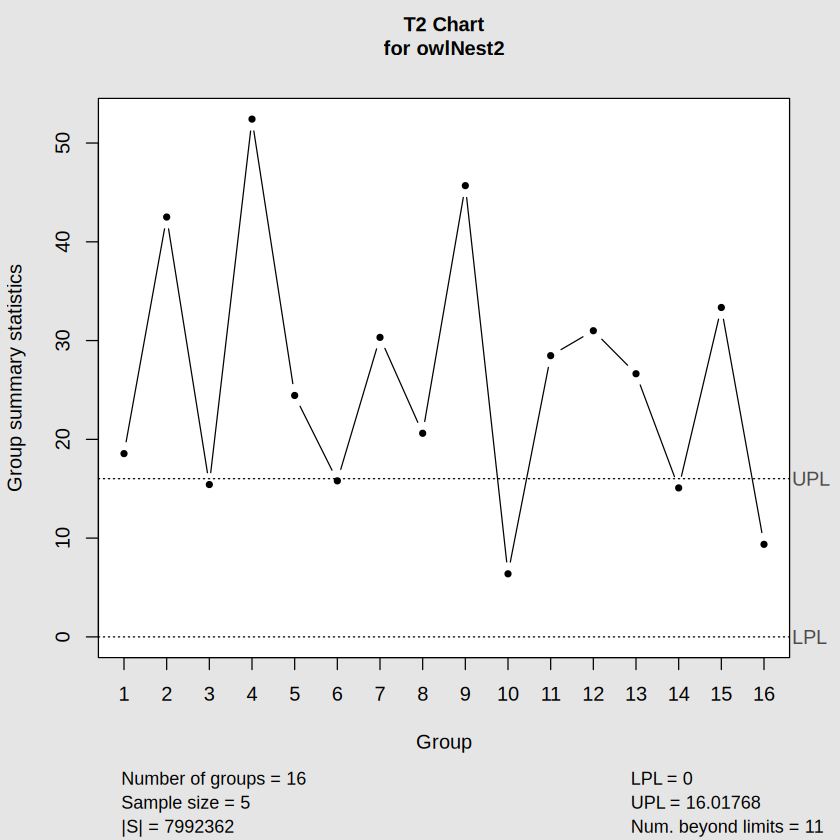

In [15]:
p2 <- mqcc(owlNest2,type="T2",
           center=t2$center, cov = t2$cov,
           limits=F, pred.limits=T,
           plot=T)

This T2 chart supports the evidence of no statistical control as there are multiple points beyond the upper limit.

In [17]:
# c4 for n = 5 is 0.94 from MIT table

c4 <- 0.94

# sample means
counselor1_xbar <- t2$center[1]
counselor2_xbar <- t2$center[2]
counselor3_xbar <- t2$center[3]
counselor4_xbar <- t2$center[4]

# variance-covariance
counselor1_sd <- sqrt(t2$cov[1,1])/c4
counselor2_sd <- sqrt(t2$cov[2,2])/c4
counselor3_sd <- sqrt(t2$cov[3,3])/c4
counselor4_sd <- sqrt(t2$cov[4,4])/c4


In [18]:
# UCL & LCL calculation

counselor1_ucl <- counselor1_xbar + 3*counselor1_sd
counselor1_lcl <- counselor1_xbar - 3*counselor1_sd

counselor2_ucl <- counselor2_xbar + 3*counselor2_sd
counselor2_lcl <- counselor2_xbar - 3*counselor2_sd

counselor3_ucl <- counselor3_xbar + 3*counselor3_sd
counselor3_lcl <- counselor3_xbar - 3*counselor3_sd

counselor4_ucl <- counselor4_xbar + 3*counselor4_sd
counselor4_lcl <- counselor4_xbar - 3*counselor4_sd

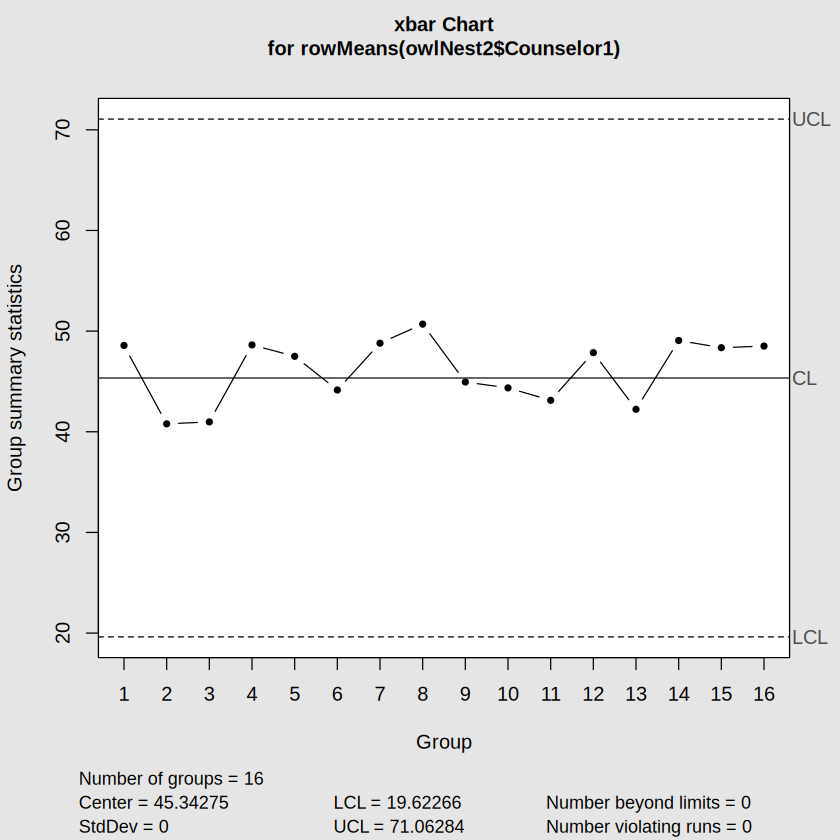

In [19]:
xbar1 <- qcc(rowMeans(owlNest2$Counselor1),
             type="xbar",
             center=counselor1_xbar,
             sigma=counselor1_sd,
             sizes=5,
             limits=c(counselor1_lcl,counselor1_ucl))

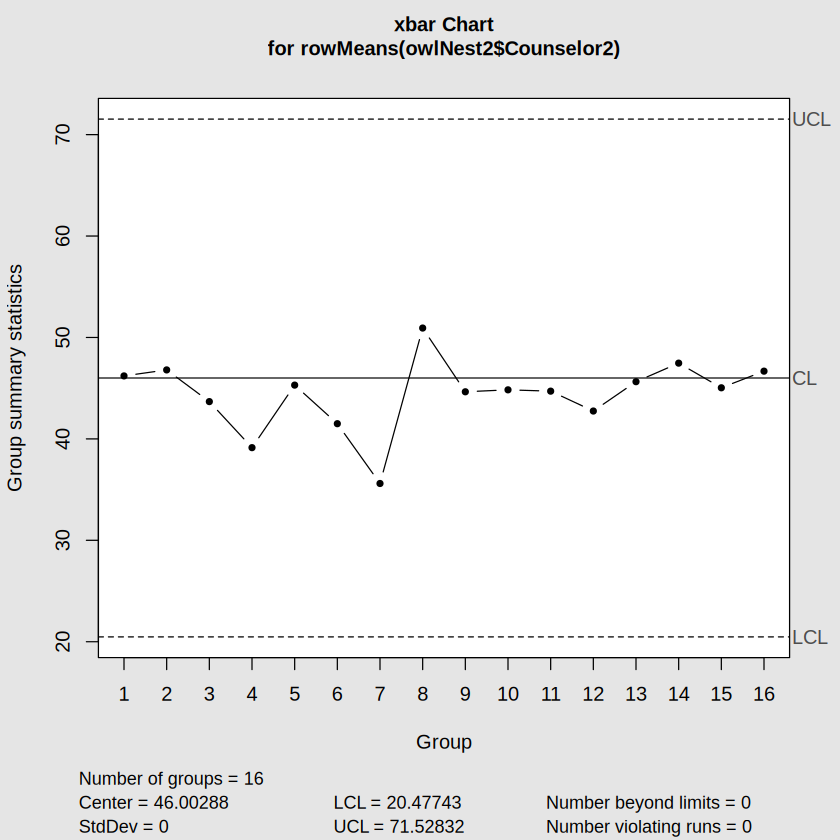

In [20]:
xbar2 <- qcc(rowMeans(owlNest2$Counselor2),
             type="xbar",
             center=counselor2_xbar,
             sigma=counselor2_sd,
             sizes=5,
             limits=c(counselor2_lcl,counselor2_ucl))

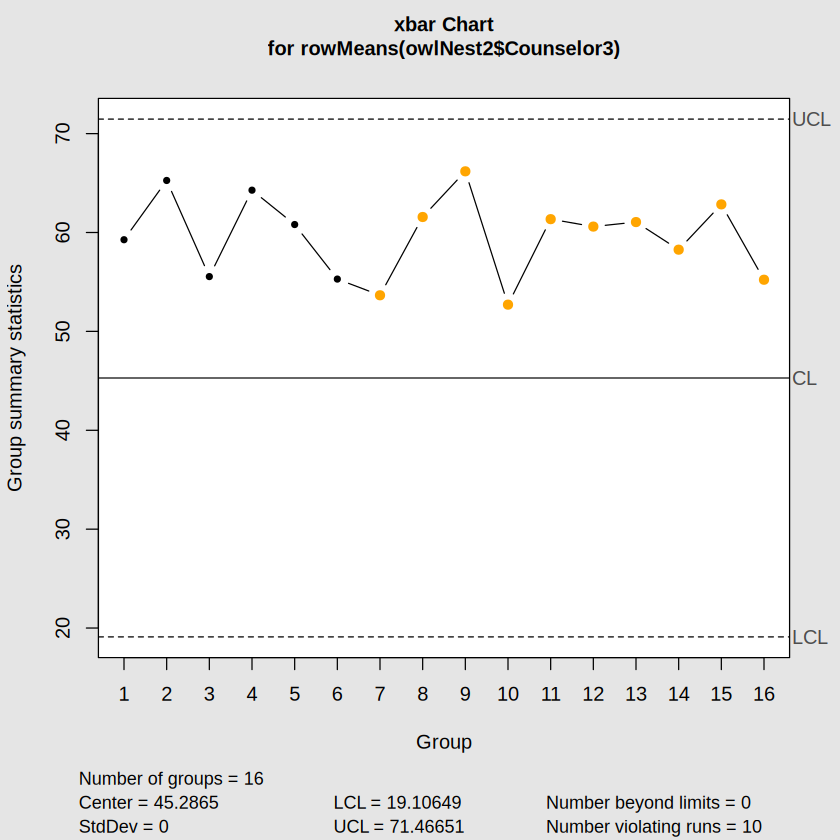

In [21]:
xbar3 <- qcc(rowMeans(owlNest2$Counselor3),
             type="xbar",
             center=counselor3_xbar,
             sigma=counselor3_sd,
             sizes=5,
             limits=c(counselor3_lcl,counselor3_ucl))

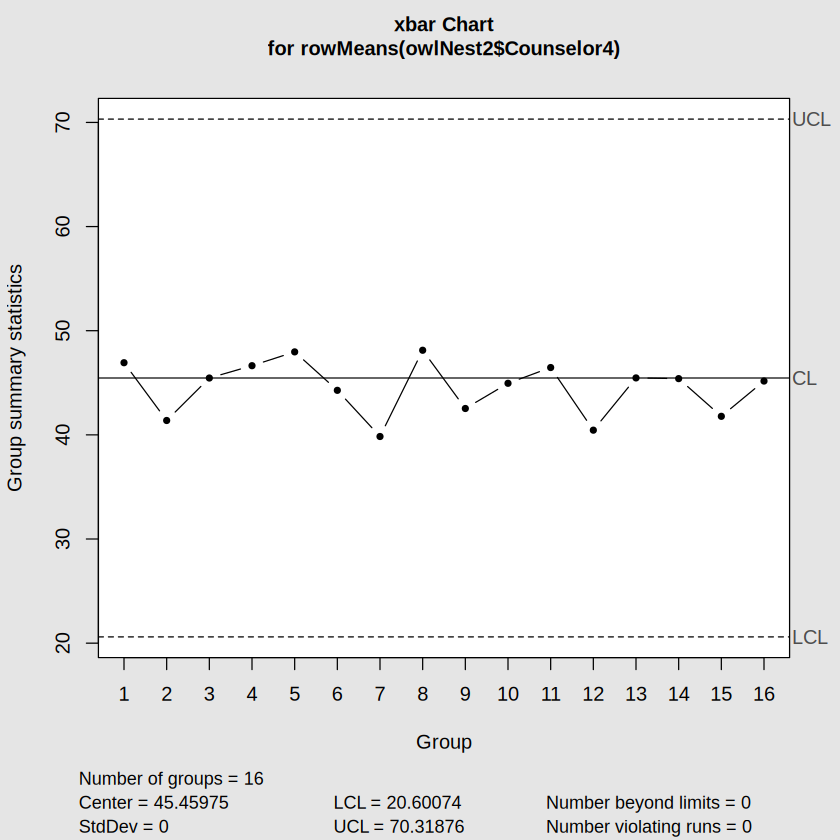

In [22]:
xbar4 <- qcc(rowMeans(owlNest2$Counselor4),
             type="xbar",
             center=counselor4_xbar,
             sigma=counselor4_sd,
             sizes=5,
             limits=c(counselor4_lcl,counselor4_ucl))

counselor 3 is statistically out of control while couselors 1, 2, & 4 are behaving normally.

### Q7: What is the benefit of using a multivariate control chart over several separate univariate control charts? What is one limitation?

## Improve

### Q8: Based on your findings in Q6, briefly describe what intervention(s) you, as the director, might reasonably take regarding the counselor(s) flagged as out of control.

## Control

### Q9: It is reasonable to assume that this same monitoring situation could also be conceptualized as a **multiple stream process (MSP)** -- that is, treating the four counselors as independent, parallel processes rather than a single correlated multivariate one. Perform the same Phase I analysis as before, but using the Control Chart for Each Stream MSP technique ($L = 3.46$). Do we have evidence of statistical control?

In [ ]:
## Q9 Code ##

### Q10: Perform Phase II analysis using the Control Chart for Each Stream MSP technique. Do we still have evidence of statistical control? If not, which stream(s) (i.e., counselors) may be causing the out-of-control point(s)?

In [ ]:
## Q10 Code ##

### Q11: What is a difference between a multivariate process and a multiple stream process? Given what you found in Q4-Q10, which framing do you think is the more defensible choice for this specific scenario, and why?

### Q12: Provide an overview of your results that you, as the director, could bring to the university's Vice President of Student Affairs. What is the current status of The Owl's Nest program, and what actions (if any) have you taken or would you recommend?